[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol20_notebook_seminar.ipynb)

# Modelarea piețelor financiare — Seminarul 20 (capitol special): Semnătura traiectoriilor și volatilitatea realizată

- **Partea A**: derivări (semnături, identitatea lui Chen, aria Lévy, modelul autoregresiv heterogen HAR ca autoregresie de ordinul 22, AR(22), pierderea de tip cvasi-verosimilitate QLIKE, ponderi de nucleu); **Partea B**: varianța realizată (RV) din datele VOLARE, cu inferență; **Partea C**: un nucleu sensibil la nivel și critica unui răspuns AI.
- Problemele rezolvate sînt complete; cele propuse dau cerința și indică modelul.

> Rezolvările se discută la seminar.

In [1]:
# Pe Colab, instalați întîi arch: !pip install arch
# Colab: !pip install arch
import os
import json
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import lars_path
import warnings
warnings.filterwarnings('ignore')

## Datele VOLARE

- VOLARE (Cipollini, Cruciani, Gallo, Insana, Otranto și Spagnolo, 2026, https://doi.org/10.48550/arXiv.2602.19732) este gratuit pentru cercetare la http://volare.unime.it.
- Descărcați `realized_variance_stocks.csv`, `realized_variance_futures.csv` și `realized_variance_forex.csv` și setați `VOLARE_DIR` la folderul lor.

In [2]:
# VOLARE is licensed for research use and is not redistributed with this course.
# Download the three realised-variance files free from http://volare.unime.it
# (realized_variance_stocks.csv, realized_variance_futures.csv, realized_variance_forex.csv)
# and set the folder that contains them (on Colab: upload them or mount Google Drive).
VOLARE_DIR = 'data/volare'
for _d in ('.', '..', '../..', '../../..'):
    if not os.path.isdir(VOLARE_DIR) and os.path.isdir(os.path.join(_d, 'data', 'volare')):
        VOLARE_DIR = os.path.join(_d, 'data', 'volare')
print('VOLARE folder:', os.path.abspath(VOLARE_DIR))

## Semnături, modele și teste

- Semnături trunchiate prin identitatea lui Chen, nucleul de semnătură, LASSO în doi pași cu criteriul informațional bayesian (BIC), repere HAR, QLIKE, testele Diebold-Mariano (DM) și Giacomini-White (GW), mulțimea de încredere a modelelor (MCS).

In [3]:
CLASSES = ('stocks', 'futures', 'forex')
COLS = ['date', 'symbol', 'open_price', 'close_price', 'rv5', 'rsp5', 'rsn5', 'rq5', 'rk']
_RAW = {}


def load_class(kind):
    """All realised measures of one VOLARE asset class (stocks, futures, forex)."""
    if kind not in _RAW:
        f = os.path.join(VOLARE_DIR, f'realized_variance_{kind}.csv')
        _RAW[kind] = pd.read_csv(f, usecols=COLS, parse_dates=['date'])
    return _RAW[kind]


def load_asset(kind, symbol):
    """Daily series of one asset: rv (5-minute RV), semivariances, quarticity, kernel, open-to-close return."""
    d = load_class(kind)
    d = d[d.symbol == symbol].sort_values('date').set_index('date')
    out = pd.DataFrame({'rv': d.rv5, 'rsp': d.rsp5, 'rsn': d.rsn5, 'rq': d.rq5, 'rk': d.rk,
                        'r': np.log(d.close_price / d.open_price)})
    out = out[(out.rv > 0) & (out.rsp >= 0) & (out.rsn >= 0) & (out.rq > 0) & np.isfinite(out.r)]
    return out[~out.index.duplicated()]


def symbols(kind):
    return sorted(load_class(kind).symbol.unique())


# -----------------------------------------------------------------------------
# SIGNATURES (numpy, Chen's identity)
# -----------------------------------------------------------------------------
def sig_words(d, depth):
    """Multi-indices (words) of the truncated signature, levels 1..depth, in the order of sig_windows."""
    return [w for k in range(1, depth + 1) for w in itertools.product(range(d), repeat=k)]


def sig_path(path, depth=3):
    """Truncated signature (levels 1..depth) of the piecewise-linear path through the rows of `path` (m x d)."""
    return sig_windows(np.asarray(path, float), len(path), depth)[-1]


def _outer(A, B):
    """Row-wise tensor product of flattened tensors: (m, d^a) x (m, d^b) -> (m, d^(a+b)), lexicographic order."""
    return (A[:, :, None] * B[:, None, :]).reshape(A.shape[0], -1)


def sig_windows(x, l, depth=3):
    """Signatures of all rolling windows of l points of the path x (n x d); row i = window ending at point i.

    Chen's identity: S(X * Y) = S(X) (x) S(Y); a linear segment with increment D has S = exp(D) =
    (1, D, D(x)D/2!, D(x)D(x)D/3!, ...), so level k of the updated signature is
    sum_{p=0..k} S_old^(k-p) (x) D^(x)p / p!.  Rows i < l-1 are NaN."""
    x = np.asarray(x, float)
    n, d = x.shape
    m = n - l + 1
    lev = [np.ones((m, 1))] + [np.zeros((m, d ** k)) for k in range(1, depth + 1)]
    for j in range(l - 1):
        D = x[j + 1:j + 1 + m] - x[j:j + m]                        # increment of segment j in every window
        pw = [np.ones((m, 1))]
        for p in range(1, depth + 1):
            pw.append(_outer(pw[-1], D) / p)                       # D^(x)p / p!
        lev = [lev[0]] + [sum(_outer(lev[k - p], pw[p]) for p in range(0, k + 1)) for k in range(1, depth + 1)]
    flat = np.concatenate(lev[1:], axis=1)
    out = np.full((n, flat.shape[1]), np.nan)
    out[l - 1:] = flat
    return out


def sig_scale(scales, depth=3):
    """Signature of a path whose channel c is multiplied by scales[c]: level-k word (i1..ik) scales by prod."""
    return np.array([np.prod([scales[i] for i in w]) for w in sig_words(len(scales), depth)])


def levy_area(path):
    """Levy area of the first two channels: (S^(1,2) - S^(2,1)) / 2."""
    S = sig_path(path, 2)
    d = np.asarray(path).shape[1]
    s2 = S[d:].reshape(d, d)
    return 0.5 * (s2[0, 1] - s2[1, 0])


def sig_kernel(Sa, Sb):
    """Truncated signature kernel <S^N(a), S^N(b)> including the level-0 term 1."""
    return 1.0 + np.dot(Sa, Sb)


def sig_distance(Sa, Sb):
    """d_Sig(a, b) = k(a,a) - 2 k(a,b) + k(b,b) = ||S^N(a) - S^N(b)||^2."""
    return sig_kernel(Sa, Sa) - 2 * sig_kernel(Sa, Sb) + sig_kernel(Sb, Sb)


# -----------------------------------------------------------------------------
# DESIGN (pre-registered, fixed before any out-of-sample result)
# -----------------------------------------------------------------------------
CFG = dict(
    W=1000,             # rolling estimation window (days of (x_tau, y_tau+h) pairs)
    K=5,                # re-estimation every K trading days (parameters fixed in between)
    L=22,               # signature lookback (points in the path), one trading month
    DEPTH=3,            # truncation depth N
    HORIZONS=(1, 5, 22),
    VAL=250,            # validation block: first 250 forecast days of every asset (only for choosing c)
    C_GRID=(0.5, 1.0, 2.0, 4.0),   # gamma = c / median(d_tau)
    CHANNELS=('t', 'logrv', 'cumret'),
)
MODELS = ['HAR', 'logHAR', 'HARQ', 'SHAR', 'logHAR-K', 'Sig-L', 'Sig-LK']
LABEL = {'HAR': 'HAR', 'logHAR': 'log-HAR', 'HARQ': 'HARQ', 'SHAR': 'SHAR', 'logHAR-K': 'log-HAR + kernel weights',
         'Sig-L': 'Signature LASSO', 'Sig-LK': 'Signature LASSO + kernel weights'}


def har_parts(v):
    """Daily, weekly (5-day) and monthly (22-day) averages of a series ending at each day."""
    s = pd.Series(v)
    return np.c_[s.values, s.rolling(5).mean().values, s.rolling(22).mean().values]


def build_design(a, h, cfg=CFG):
    """Features and targets of one asset for horizon h (arrays aligned on the asset's trading days)."""
    rv = a.rv.values
    n = len(rv)
    lrv = np.log(rv)
    y = pd.Series(rv).rolling(h).mean().shift(-h).values       # mean RV over days t+1..t+h
    H = har_parts(rv)
    D = dict(dates=a.index, rv=rv, y=y, ly=np.log(y), n=n, h=h)
    D['X_har'] = H
    D['X_loghar'] = np.log(H)
    D['sqrq'] = np.sqrt(a.rq.values)
    D['X_shar'] = np.c_[a.rsp.values, a.rsn.values, H[:, 1], H[:, 2]]
    # path for the signature: (time, log RV, cumulative open-to-close return), channels as in cfg
    chan = {'t': np.arange(n, dtype=float) / (cfg['L'] - 1), 'logrv': lrv, 'cumret': np.cumsum(a.r.values),
            'rsn': np.log(np.maximum(a.rsn.values, 1e-12))}
    P = np.column_stack([chan[c] for c in cfg['CHANNELS']])
    D['path'] = P
    D['sig'] = sig_windows(P, cfg['L'], cfg['DEPTH'])
    D['incr'] = np.r_[np.full((1, P.shape[1]), np.nan), np.diff(P, axis=0)]
    return D


# -----------------------------------------------------------------------------
# ESTIMATION
# -----------------------------------------------------------------------------
def wls(X, y, w):
    """Weighted least squares with intercept; returns coefficients (b0, b) and weighted residual variance."""
    Z = np.c_[np.ones(len(y)), X]
    sw = np.sqrt(w)
    b, *_ = np.linalg.lstsq(Z * sw[:, None], y * sw, rcond=None)
    e = y - Z @ b
    return b, float(np.sum(w * e ** 2) / np.sum(w))


def two_step_lasso(X, y, w, max_steps=60):
    """Weighted LASSO path (LARS) -> OLS refit on each support -> BIC with Kish effective sample size.

    Step 1 (Gu et al., 2024, Eq. 14): min_theta sum_tau w_tau (y - x theta)^2 + lambda ||theta||_1.
    Step 2 (Eq. 15): weighted OLS on supp(theta_LASSO).  lambda chosen by BIC inside the window."""
    w = w / w.sum()
    n_eff = 1.0 / np.sum(w ** 2)
    mx = w @ X
    my = w @ y
    sd = np.sqrt(w @ (X - mx) ** 2)
    keep = sd > 1e-12
    Xs = (X[:, keep] - mx[keep]) / sd[keep]
    sw = np.sqrt(w)
    _, _, coefs = lars_path(Xs * sw[:, None], (y - my) * sw, method='lasso', max_iter=max_steps)
    idx = np.where(keep)[0]
    best, seen = None, set()
    for j in range(coefs.shape[1]):
        S = tuple(idx[np.abs(coefs[:, j]) > 0])
        if S in seen:
            continue
        seen.add(S)
        b, s2 = wls(X[:, list(S)], y, w) if S else (np.array([my]), float(w @ (y - my) ** 2))
        bic = n_eff * np.log(s2) + (len(S) + 1) * np.log(n_eff)
        if best is None or bic < best[0]:
            best = (bic, S, b, s2)
    _, S, b, s2 = best
    beta = np.zeros(X.shape[1])
    beta[list(S)] = b[1:]
    return b[0], beta, s2, S


def kernel_weights(sig_train, sig_now, scale, c):
    """w_tau proportional to exp(-gamma d_Sig(window tau, current window)), gamma = c / median(d)."""
    diff = (sig_train - sig_now) * scale
    d = np.sum(diff ** 2, axis=1)
    g = c / np.median(d)
    z = -g * d
    w = np.exp(z - z.max())
    return w / w.sum(), d


def insanity(fc, models):
    """Bollerslev, Patton & Quaedvlieg (2016) filter: a forecast outside the range of the target in the estimation
    window is replaced by the window mean (columns lo, hi, mu of a forecast table)."""
    out = fc.copy()
    for m in models:
        bad = (fc[m] < fc.lo) | (fc[m] > fc.hi)
        out.loc[bad, m] = fc.mu[bad]
    return out


def fit_models(D, t, cfg, c_sig, c_har, models=MODELS, keep_weights=False):
    """Estimate every model at origin t (information up to day t); return a dict of forecast functions."""
    h, W, L = D['h'], cfg['W'], cfg['L']
    tr = np.arange(t - h - W + 1, t - h + 1)                     # tau with tau + h <= t
    y, ly = D['y'][tr], D['ly'][tr]
    uni = np.full(len(tr), 1.0 / len(tr))
    out, info = {}, {}
    if 'HAR' in models:
        b, _ = wls(D['X_har'][tr], y, uni)
        out['HAR'] = ('lvl', b, None, 0.0)
    if 'logHAR' in models:
        b, s2 = wls(D['X_loghar'][tr], ly, uni)
        out['logHAR'] = ('log', b, None, s2)
    if 'HARQ' in models:
        mq = D['sqrq'][tr].mean()
        X = np.c_[D['X_har'][tr, 0], D['X_har'][tr, 0] * (D['sqrq'][tr] - mq), D['X_har'][tr, 1:]]
        b, _ = wls(X, y, uni)
        out['HARQ'] = ('harq', b, mq, 0.0)
    if 'SHAR' in models:
        b, _ = wls(D['X_shar'][tr], y, uni)
        out['SHAR'] = ('shar', b, None, 0.0)
    need_sig = any(m in models for m in ('Sig-L', 'Sig-LK', 'logHAR-K'))
    if need_sig:
        # channel scales from the training window: each non-time channel / (sd of daily increments * sqrt(L-1))
        inc = D['incr'][tr[0]:t + 1]
        sc = []
        for j, cname in enumerate(cfg['CHANNELS']):
            sc.append(1.0 if cname == 't' else 1.0 / (np.nanstd(inc[:, j]) * np.sqrt(L - 1)))
        scale = sig_scale(np.array(sc), cfg['DEPTH'])
        Str = D['sig'][tr]
        Xsig = np.c_[D['X_loghar'][tr], Str * scale]
        if 'Sig-L' in models:
            b0, beta, s2, sup = two_step_lasso(Xsig, ly, uni)
            out['Sig-L'] = ('sig', np.r_[b0, beta], scale, s2)
            info['k_Sig-L'] = len(sup)
            info['S_Sig-L'] = ' '.join(map(str, sup))
        wk, dist = kernel_weights(Str, D['sig'][t], scale, c_sig)
        if 'Sig-LK' in models:
            b0, beta, s2, sup = two_step_lasso(Xsig, ly, wk)
            out['Sig-LK'] = ('sig', np.r_[b0, beta], scale, s2)
            info['k_Sig-LK'] = len(sup)
            info['S_Sig-LK'] = ' '.join(map(str, sup))
            info['ess'] = 1.0 / np.sum(wk ** 2)
            top = D['rv'][tr] >= np.quantile(D['rv'][tr], 0.9)
            info['hv_share'] = float(wk[top].sum())             # weight on the 10% most volatile training days
            info['date'] = D['dates'][t]
            if keep_weights:
                info['weights'] = pd.Series(wk, index=D['dates'][tr])
        if 'logHAR-K' in models:
            wh = wk if c_har == c_sig else kernel_weights(Str, D['sig'][t], scale, c_har)[0]
            b, s2 = wls(D['X_loghar'][tr], ly, wh)
            out['logHAR-K'] = ('log', b, None, s2)
    return out, info, (y.min(), y.max(), y.mean())


def predict(D, s, spec):
    kind, b, extra, s2 = spec
    if kind == 'lvl':
        return b[0] + D['X_har'][s] @ b[1:]
    if kind == 'shar':
        return b[0] + D['X_shar'][s] @ b[1:]
    if kind == 'harq':
        Xh = D['X_har'][s]
        X = np.c_[Xh[:, 0], Xh[:, 0] * (D['sqrq'][s] - extra), Xh[:, 1:]]
        return b[0] + X @ b[1:]
    if kind == 'log':
        return np.exp(b[0] + D['X_loghar'][s] @ b[1:] + 0.5 * s2)
    if kind == 'sig':
        X = np.c_[D['X_loghar'][s], D['sig'][s] * extra]
        return np.exp(b[0] + X @ b[1:] + 0.5 * s2)
    raise ValueError(kind)


def first_origin(D, cfg):
    """First forecast origin: HAR needs 22 days, the signature L points, the training window W pairs."""
    return max(22, cfg['L']) + cfg['W'] + D['h']


def eval_start(D, cfg, cutoff=None):
    """First evaluation origin: after the asset's validation block + h days and, if given, strictly after the date of
    the last validation target of its asset class (cutoff), so that no evaluated origin precedes a tuning target."""
    st = first_origin(D, cfg) + cfg['VAL'] + D['h']
    if cutoff is not None:
        st = max(st, int(D['dates'].searchsorted(pd.Timestamp(cutoff), side='right')))
    return st


def tuned(res, kind, h):
    """(c for Sig-LK, c for log-HAR-K, class cutoff date) chosen on the validation block of the asset class
    (from ch20_results.json: keys 'validation' and 'val_cutoff')."""
    v = res['validation']
    return v[f'{kind}|Sig-LK|{h}']['c'], v[f'{kind}|logHAR-K|{h}']['c'], res['val_cutoff'][f'{kind}|{h}']


def run_forecasts(D, cfg, c_sig, c_har, start, stop, models=MODELS, weight_dates=()):
    """Rolling forecasts for origins start..stop-1; re-estimation every cfg['K'] days.
    For a date in weight_dates the kernel weights are recomputed at that exact origin (diagnostic; the forecast of that
    day still uses the coefficients estimated at the start of its 5-day block)."""
    rows, ks, wsave = [], [], {}
    wd = set(pd.DatetimeIndex(weight_dates))
    t = start
    while t < stop:
        blk = np.arange(t, min(t + cfg['K'], stop))
        specs, info, (lo, hi, mu) = fit_models(D, t, cfg, c_sig, c_har, models)
        for s in blk:
            if D['dates'][s] in wd:
                _, inf_s, _ = fit_models(D, s, cfg, c_sig, c_har, ['Sig-LK'], keep_weights=True)
                wsave[D['dates'][s]] = inf_s.get('weights')
        f = {m: predict(D, blk, specs[m]) for m in models}
        for m in models:                                          # positivity: QLIKE needs f > 0
            v = f[m]
            f[m] = np.where((v <= 0) | ~np.isfinite(v), mu, v)
        for i, s in enumerate(blk):
            rows.append([D['dates'][s], D['y'][s], lo, hi, mu] + [f[m][i] for m in models])
        ks.append({k: v for k, v in info.items() if k != 'weights'})
        t += cfg['K']
    fc = pd.DataFrame(rows, columns=['date', 'y', 'lo', 'hi', 'mu'] + list(models)).set_index('date')
    return fc, pd.DataFrame(ks), wsave


# -----------------------------------------------------------------------------
# EVALUATION
# -----------------------------------------------------------------------------
def qlike(y, f):
    """QLIKE(y, f) = y/f - log(y/f) - 1 (Patton, 2011): y is the realised proxy, f the forecast."""
    r = y / f
    return r - np.log(r) - 1.0


def mse(y, f):
    return (y - f) ** 2


def nw_var(d, lag):
    """Newey-West (Bartlett) long-run variance of a series."""
    d = np.asarray(d, float) - np.mean(d)
    T = len(d)
    v = d @ d / T
    for j in range(1, lag + 1):
        v += 2 * (1 - j / (lag + 1)) * (d[j:] @ d[:-j]) / T
    return v


def nw_lag(T, h):
    return int(max(h, np.ceil(T ** (1 / 3))))


def dm_test(la, lb, h):
    """Diebold-Mariano: d = L_A - L_B; t = mean(d) / sqrt(NW var / T); one-sided p for 'A beats B' (d < 0)."""
    d = np.asarray(la) - np.asarray(lb)
    T = len(d)
    t = d.mean() / np.sqrt(nw_var(d, nw_lag(T, h)) / T)
    return t, stats.norm.cdf(t), 2 * stats.norm.sf(abs(t))


def gw_test(la, lb, h):
    """Giacomini-White conditional test, instruments (1, d_{t-h}); Wald ~ chi2(2)."""
    d = np.asarray(la) - np.asarray(lb)
    Z = np.c_[np.ones(len(d) - h), d[:-h]] * d[h:, None]
    T = len(Z)
    zb = Z.mean(0)
    Zc = Z - zb
    lag = nw_lag(T, h)
    O = Zc.T @ Zc / T
    for j in range(1, lag + 1):
        G = Zc[j:].T @ Zc[:-j] / T
        O += (1 - j / (lag + 1)) * (G + G.T)
    stat = T * zb @ np.linalg.solve(O, zb)
    return stat, stats.chi2.sf(stat, 2)


def holm(p):
    p = np.asarray(p)
    o = np.argsort(p)
    m = len(p)
    adj = np.maximum.accumulate((m - np.arange(m)) * p[o])
    out = np.empty(m)
    out[o] = np.minimum(adj, 1)
    return out


def bh(p):
    p = np.asarray(p)
    o = np.argsort(p)
    m = len(p)
    adj = np.minimum.accumulate((m / np.arange(m, 0, -1)) * p[o][::-1])[::-1]
    out = np.empty(m)
    out[o] = np.minimum(adj, 1)
    return out


def mcs(losses, size=0.10, reps=1000, block=None, seed=20):
    """Model confidence set (Hansen, Lunde & Nason, 2011), T_max statistic, stationary bootstrap."""
    try:
        from arch.bootstrap import MCS
    except ModuleNotFoundError as exc:
        if exc.name != 'arch':
            raise
        import subprocess
        import sys
        subprocess.run([sys.executable, '-m', 'pip', 'install', 'arch'], check=True)
        from arch.bootstrap import MCS
    L = pd.DataFrame(losses)
    m = MCS(L, size=size, reps=reps, block_size=block or 10, method='max', bootstrap='stationary', seed=seed)
    m.compute()
    return list(m.included), m.pvalues['Pvalue'].to_dict()

## Stilul graficelor

In [4]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Course colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'
COL = {'HAR': MainBlue, 'logHAR': Teal, 'HARQ': Purple, 'SHAR': Amber, 'logHAR-K': Orange,
       'Sig-L': Forest, 'Sig-LK': IDAred}
SHORT = {'HAR': 'HAR', 'logHAR': 'log-HAR', 'HARQ': 'HARQ', 'SHAR': 'SHAR', 'logHAR-K': 'log-HAR-K',
         'Sig-L': 'Sig-L', 'Sig-LK': 'Sig-LK'}
CLASS_LABEL = {'stocks': 'US stocks (40)', 'futures': 'Futures (5)', 'forex': 'FX (5)', 'all': 'All 50 assets'}
PERIODS = {'covid': ('2020-02-20', '2020-04-30'), 'apr2025': ('2025-04-02', '2025-04-30')}
H = CFG['HORIZONS']


def save_fig(name):
    """Show the figure (the Quantlet folder contains the saved PDF/PNG)."""
    plt.show()
    plt.close()


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def fig_legend_bottom(fig, axes, ncol=4, y=0.0):
    """One legend below a figure with several panels."""
    h, l = [], []
    for ax in axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l:
                h.append(hh)
                l.append(ll)
    fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)

## Funcțiile seminarului

In [5]:
RES = {}


def lecture_results():
    """Results of the Lecture 20 case study (DM p-values and tuned kernel temperatures), loaded from the course repository."""
    for d in ('.', '../MFM_ch20_case_study', '../../Quantlets/Ch_20', '../Quantlets/Ch_20'):
        f = os.path.join(d, 'ch20_results.json')
        if os.path.exists(f):
            return json.load(open(f))
    import urllib.request
    url = 'https://raw.githubusercontent.com/danpele/MFM/main/Quantlets/Ch_20/MFM_ch20_case_study/ch20_results.json'
    return json.load(urllib.request.urlopen(url))


# seminar charts sit next to the solution bullets: larger fonts than the lecture charts
BIG = {'font.size': 11, 'axes.labelsize': 11, 'axes.titlesize': 11, 'xtick.labelsize': 10.5,
       'ytick.labelsize': 10.5, 'legend.fontsize': 10.5}


def big(fn):
    def wrapped(*a, **k):
        with plt.rc_context(BIG):
            return fn(*a, **k)
    wrapped.__name__ = fn.__name__
    return wrapped


def ols_hac(y, X, lag):
    """OLS with Newey-West standard errors; X without constant."""
    Z = np.c_[np.ones(len(y)), X]
    b = np.linalg.lstsq(Z, y, rcond=None)[0]
    e = y - Z @ b
    T = len(y)
    Zi = np.linalg.inv(Z.T @ Z)
    G = (Z * e[:, None])
    Sg = G.T @ G / T
    for j in range(1, lag + 1):
        C = G[j:].T @ G[:-j] / T
        Sg += (1 - j / (lag + 1)) * (C + C.T)
    V = T * Zi @ Sg @ Zi
    return b, np.sqrt(np.diag(V)), V


# -----------------------------------------------------------------------------
# PART A
# -----------------------------------------------------------------------------
def part_a():
    A = {}
    # A1: time-augmented path of a series y = (0, 2, 3, 3) at t = (0, 1, 2, 3)
    P = np.array([[0, 0], [1, 2], [2, 3], [3, 3]], float)
    s = sig_path(P, 2)
    A['a1'] = {'lvl1': s[:2].tolist(), 'lvl2': s[2:].reshape(2, 2).tolist(), 'levy': levy_area(P)}
    # A7: HAR as a restricted AR(22) for log RV of JPM, regressors = arithmetic averages of log RV (daily, 5, 22 days);
    # the benchmark log-HAR of the lecture uses logs of averages of RV and has no exact AR(22) representation
    a = load_asset('stocks', 'JPM')
    D = build_design(a, 1)
    Xl = har_parts(np.log(a.rv.values))
    ok = np.isfinite(Xl).all(1) & np.isfinite(D['ly'])
    b, se, _ = ols_hac(D['ly'][ok], Xl[ok], 5)
    phi = np.r_[b[1] + b[2] / 5 + b[3] / 22, np.repeat(b[2] / 5 + b[3] / 22, 4), np.repeat(b[3] / 22, 17)]
    bl, _, _ = ols_hac(D['ly'][ok], D['X_loghar'][ok], 5)      # logs of averages, for comparison
    A['a5'] = {'b': b.tolist(), 'se': se.tolist(), 'phi1': phi[0], 'phi2': phi[1], 'phi6': phi[5], 'sum': phi.sum(),
               'N': int(ok.sum()), 'b_logavg': bl.tolist(), 'phi_min': float(phi.min())}
    # A2: QLIKE of +/-50% errors
    A['a7'] = {'under': float(qlike(1.0, 0.5)), 'over': float(qlike(1.0, 1.5)),
               'mse_under': 0.25, 'mse_over': 0.25}
    # A3: kernel weights for distances (0.2, 0.5, 1.0, 2.0), gamma = 1 and gamma = 3
    d = np.array([0.2, 0.5, 1.0, 2.0])
    for g in (1.0, 3.0):
        w = np.exp(-g * d) / np.exp(-g * d).sum()
        A[f'a9_g{int(g)}'] = {'w': w.tolist(), 'ess': float(1 / np.sum(w ** 2))}
    RES['A'] = A
    chart_a1(P)
    chart_a5(phi)
    chart_a7()
    chart_a9(d)


def setup_check():
    """What the setup cell must print: size and first rows of the JPM file."""
    a = load_asset('stocks', 'JPM')
    RES['setup'] = {'n': int(len(a)), 'start': str(a.index[0].date()), 'end': str(a.index[-1].date()),
                    'head': [[str(i.date()), float(r.rv), float(r.r)] for i, r in a.head(3).iterrows()],
                    'n_stocks': len(symbols('stocks')), 'n_futures': len(symbols('futures')),
                    'n_forex': len(symbols('forex'))}


@big
def chart_a1(P):
    """A1: the time-augmented path, its chord and the enclosed signed area."""
    fig, ax = plt.subplots(figsize=(4.2, 3.4))
    ax.fill(np.r_[P[:, 0], P[0, 0]], np.r_[P[:, 1], P[0, 1]], color=IDAred, alpha=0.18,
            label='Area between path and chord (2, run clockwise: A = -2)')
    ax.plot(P[:, 0], P[:, 1], color=MainBlue, lw=1.8, marker='o', label='Path X = (t, y)')
    ax.plot([P[0, 0], P[-1, 0]], [P[0, 1], P[-1, 1]], color=Gray, ls='--', lw=1.0, label='Chord from start to end')
    for t_, y_ in P:
        ax.annotate(f'({t_:.0f}, {y_:.0f})', (t_, y_), xytext=(5, 10), textcoords='offset points', fontsize=9, bbox=dict(facecolor='white',edgecolor='none',alpha=.9,pad=.6),
                    color='black')
    ax.set_xlabel('Time t (channel 1)')
    ax.set_ylabel('y (channel 2)')
    ax.set_xlim(-0.3, 3.5)
    ax.set_ylim(-0.6, 3.6)
    legend_outside_bottom(ax, ncol=1, y=-0.18)
    save_fig('ch20_sem_a1_path')





@big
def chart_a5(phi):
    """A7: the AR(22) coefficients implied by the HAR with averages of logs (JPM)."""
    fig, ax = plt.subplots(figsize=(5.6, 3.0))
    lags = np.arange(1, 23)
    col = [IDAred] + [Orange] * 4 + [MainBlue] * 17
    ax.bar(lags, phi, color=col, width=0.7)
    for c_, lab in [(IDAred, 'Lag 1: daily + weekly + monthly terms'), (Orange, 'Lags 2-5: weekly + monthly terms'),
                    (MainBlue, 'Lags 6-22: monthly term only')]:
        ax.bar([np.nan], [np.nan], color=c_, label=lab)
    ax.set_xlabel('Lag j (days)')
    ax.set_ylabel('Implied coefficient phi_j')
    ax.set_xticks([1, 5, 10, 15, 22])
    legend_outside_bottom(ax, ncol=1, y=-0.22)
    save_fig('ch20_sem_a7_phi')


@big
def chart_a7():
    """A2: QLIKE(1, F) against the squared error as functions of the forecast F."""
    F = np.linspace(0.25, 2.5, 400)
    fig, ax = plt.subplots(figsize=(5.0, 3.3))
    ax.plot(F, qlike(1.0, F), color=MainBlue, lw=1.6, label='QLIKE(RV = 1, F)')
    ax.plot(F, (1 - F) ** 2, color=Orange, lw=1.6, ls='-.', label='Squared error (1 - F)^2')
    for f_ in (0.5, 1.5):
        ax.plot([f_], [qlike(1.0, f_)], 'o', color=IDAred if f_ < 1 else Forest,
                label=f'F = {f_}: QLIKE {float(qlike(1.0, f_)):.3f}')
    ax.axvline(1, color=Gray, ls='--', lw=0.8)
    ax.set_xlabel('Forecast F (true RV = 1)')
    ax.set_ylabel('Loss')
    ax.set_ylim(0, 0.8)
    legend_outside_bottom(ax, ncol=2, y=-0.2)
    save_fig('ch20_sem_a2_qlike')


@big
def chart_a9(d):
    """A3: softmax kernel weights for three temperatures and their effective sample sizes."""
    fig, ax = plt.subplots(figsize=(5.4, 3.2))
    x = np.arange(len(d))
    for i, (g, c_) in enumerate([(0.0, Teal), (1.0, MainBlue), (3.0, IDAred)]):
        w = np.exp(-g * d) / np.exp(-g * d).sum()
        ax.bar(x + (i - 1) * 0.26, w, width=0.26, color=c_,
               label=f'gamma = {g:.0f}: n_eff = {1 / np.sum(w ** 2):.2f}')
    ax.set_xticks(x)
    ax.set_xticklabels([f'window {k + 1}\ndistance {v}' for k, v in enumerate(d)])
    ax.set_ylabel('Weight w')
    legend_outside_bottom(ax, ncol=1, y=-0.28)
    save_fig('ch20_sem_a3_weights')


# -----------------------------------------------------------------------------
# PART B
# -----------------------------------------------------------------------------
def levy_regression(kind, sym, chart):
    """Does the Levy area (return, log RV) of the last 22 days predict the next-month change of log RV?"""
    a = load_asset(kind, sym)
    D = build_design(a, 22)
    P = D['path']                                   # (t, log RV, cumulative return)
    sig = sig_windows(P[:, [2, 1]], 22, 2)        # channels (return, log RV) only: level 2 gives the area
    levy = 0.5 * (sig[:, 3] - sig[:, 4])
    y = D['ly'] - D['X_loghar'][:, 2]               # log of next-month RV minus log of past-month mean RV
    X = np.c_[D['X_loghar'], levy / np.nanstd(levy)]
    ok = np.isfinite(X).all(1) & np.isfinite(y)
    b, se, _ = ols_hac(y[ok], X[ok], 22)
    b0, se0, _ = ols_hac(y[ok], X[ok][:, :3], 22)
    e1 = y[ok] - np.c_[np.ones(ok.sum()), X[ok]] @ b
    e0 = y[ok] - np.c_[np.ones(ok.sum()), X[ok][:, :3]] @ b0
    r2 = 1 - e1.var() / y[ok].var()
    r20 = 1 - e0.var() / y[ok].var()
    chart_levy(y[ok], X[ok][:, :3], X[ok][:, 3], b[4], se[4], sym, chart)
    return {'b_levy': b[4], 'se_levy': se[4], 't_levy': b[4] / se[4], 'r2': r2, 'r2_base': r20,
            'N': int(ok.sum()), 'mean_levy': float(np.nanmean(levy)),
            'frac_neg': float(np.mean(levy[np.isfinite(levy)] < 0))}


@big
def chart_levy(y, Xb, A, b, se, sym, name):
    """Binned scatter (Frisch-Waugh): target and Levy area, both residualised on the log-HAR terms."""
    Z = np.c_[np.ones(len(y)), Xb]
    res = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
    A = A - Z @ np.linalg.lstsq(Z, A, rcond=None)[0]
    q = pd.qcut(A, 20, labels=False)
    xb = pd.Series(A).groupby(q).mean()
    yb = pd.Series(res).groupby(q).mean()
    fig, ax = plt.subplots(figsize=(5.4, 3.3))
    ax.scatter(xb, yb, color=MainBlue, s=22, zorder=3, label=f'{sym}: mean of 20 equal-count bins')
    xx = np.linspace(xb.min(), xb.max(), 50)
    ax.plot(xx, b * xx, color=IDAred, lw=1.5, label=f'OLS slope {b:.3f} (HAC s.e. {se:.3f})')
    ax.fill_between(xx, (b - 1.96 * se) * xx, (b + 1.96 * se) * xx, color='#C5D2E8', alpha=0.7,
                    label='95% HAC band of the slope')
    ax.axhline(0, color=Gray, ls='--', lw=0.8)
    ax.set_xlabel('Standardised Levy area A_t, residual on log-HAR terms')
    ax.set_ylabel('Next-month change of log RV,\nresidual on log-HAR terms')
    legend_outside_bottom(ax, ncol=1, y=-0.22)
    save_fig(name)


@big
def chart_coef(out, sym, name):
    """SHAR semivariance coefficients and the HARQ coefficient with 95% HAC intervals."""
    fig, axes = plt.subplots(1, 2, figsize=(5.67, 2.3), gridspec_kw={'width_ratios': [2, 1]})
    b, se = out['shar']['b'], out['shar']['se']
    ax = axes[0]
    for i, (k, lab, c_) in enumerate([(1, 'beta+ (positive semivariance)', Forest),
                                      (2, 'beta- (negative semivariance)', IDAred)]):
        ax.errorbar([i], [b[k]], yerr=[1.96 * se[k]], fmt='o', color=c_, capsize=4, label=('SHAR beta+' if k==1 else 'SHAR beta−'))
    ax.axhline(0, color=Gray, ls='--', lw=0.8)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['beta+', 'beta-'])
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylabel('Coefficient')
    ax.set_title(f'{sym}: SHAR', fontsize=12)
    ax = axes[1]
    bq, sq = out['harq']['b'][2], out['harq']['se'][2]
    ax.errorbar([0], [bq], yerr=[1.96 * sq], fmt='s', color=Purple, capsize=4, label='HARQ beta_Q')
    ax.axhline(0, color=Gray, ls='--', lw=0.8)
    ax.set_xticks([0])
    ax.set_xticklabels(['beta_Q'])
    ax.set_xlim(-0.8, 0.8)
    ax.set_title(f'{sym}: HARQ', fontsize=12)
    fig.suptitle('Coefficients and 95% HAC intervals', fontsize=11, y=.99)
    fig.subplots_adjust(left=.12,right=.98,top=.78,bottom=.30,wspace=.55)
    handles, labels = [], []
    for ax in axes:
        ax.tick_params(labelsize=12)
        ax.xaxis.label.set_fontsize(12); ax.yaxis.label.set_fontsize(12)
        h, l = ax.get_legend_handles_labels(); handles += h; labels += l
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(.53,0), ncol=3, frameon=False, fontsize=10.5)
    save_fig(name)





@big
def chart_pvalues(p, h, comp, name):
    """Sorted one-sided DM p-values of the 50 assets against the 5%, Holm and BH thresholds."""
    m = len(p)
    k = np.arange(1, m + 1)
    ps = np.sort(p)
    fig, ax = plt.subplots(figsize=(5.4, 3.3))
    ax.scatter(k, ps, color=MainBlue, s=14, zorder=3, label=f'Sorted p-values, {comp}, h = {h}')
    ax.axhline(0.05, color=Orange, lw=1.2, label='5% without correction')
    ax.step(k, 0.05 / (m - k + 1), where='mid', color=IDAred, lw=1.2, label='Holm: 0.05 / (m - k + 1)')
    ax.plot(k, 0.05 * k / m, color=Forest, lw=1.2, ls='-.', label='BH: 0.05 k / m')
    ax.set_yscale('log')
    ax.set_xlabel('Rank k of the p-value (m = 50 assets)')
    ax.set_ylabel('One-sided DM p-value (log scale)')
    legend_outside_bottom(ax, ncol=1, y=-0.2)
    save_fig(name)


def har_family(kind, sym):
    a = load_asset(kind, sym)
    D = build_design(a, 1)
    ok = np.isfinite(D['X_har']).all(1) & np.isfinite(D['y'])
    y = D['y'][ok]
    out = {'N': int(ok.sum())}
    b, se, _ = ols_hac(y, D['X_har'][ok], 5)
    out['har'] = {'b': b.tolist(), 'se': se.tolist()}
    b, se, V = ols_hac(y, D['X_shar'][ok], 5)
    diff = b[2] - b[1]
    sd = np.sqrt(V[2, 2] + V[1, 1] - 2 * V[1, 2])
    out['shar'] = {'b': b.tolist(), 'se': se.tolist(), 'diff': diff, 't_diff': diff / sd,
                   'p_diff': float(stats.norm.sf(diff / sd))}
    sq = D['sqrq'][ok]
    Xq = np.c_[D['X_har'][ok, 0], D['X_har'][ok, 0] * (sq - sq.mean()), D['X_har'][ok, 1:]]
    b, se, _ = ols_hac(y, Xq, 5)
    out['harq'] = {'b': b.tolist(), 'se': se.tolist(), 't_q': b[2] / se[2]}
    chart_coef(out, sym, f'ch20_sem_{"b3" if sym == "JPM" else "b4"}_coef')
    return out


def block_boot_ratio(la, lb, block=10, B=2000, seed=20):
    """Stationary-bootstrap CI for mean(la) / mean(lb)."""
    rng = np.random.default_rng(seed)
    T = len(la)
    p = 1.0 / block
    stats_ = []
    for _ in range(B):
        idx = np.empty(T, int)
        idx[0] = rng.integers(T)
        for i in range(1, T):
            idx[i] = rng.integers(T) if rng.random() < p else (idx[i - 1] + 1) % T
        stats_.append(la[idx].mean() / lb[idx].mean())
    return np.percentile(stats_, [2.5, 97.5]).tolist()


def sig_vs_loghar(kind, sym, h, c, cutoff=None):
    cfg = dict(CFG)
    a = load_asset(kind, sym)
    D = build_design(a, h, cfg)
    st = eval_start(D, cfg, cutoff)
    fc, info, _ = run_forecasts(D, cfg, c, c, st, len(a) - h, models=['logHAR', 'Sig-LK'])
    qa, qb = qlike(fc.y.values, fc['Sig-LK'].values), qlike(fc.y.values, fc['logHAR'].values)
    t, p1, p2 = dm_test(qa, qb, h)
    gw, pgw = gw_test(qa, qb, h)
    ci = block_boot_ratio(qa, qb, block=max(h, 10), B=1000)
    return {'T': len(fc), 'start': str(fc.index[0].date()), 'end': str(fc.index[-1].date()),
            'ql_sig': float(qa.mean()), 'ql_har': float(qb.mean()), 'ratio': float(qa.mean() / qb.mean()),
            'ci': ci, 't': float(t), 'p1': float(p1), 'p2': float(p2), 'gw': float(gw), 'p_gw': float(pgw),
            'k': float(info['k_Sig-LK'].mean()), 'ess': float(info['ess'].mean())}, fc


@big
def chart_cumloss(fc, sym, h, name):
    """Cumulative QLIKE difference Sig-LK minus log-HAR: upward = log-HAR better."""
    d = (qlike(fc.y, fc['Sig-LK']) - qlike(fc.y, fc['logHAR'])).cumsum()
    fig, ax = plt.subplots(figsize=(5.6, 3.0))
    ax.plot(d.index, d, color=IDAred, lw=1.1, label=f'Cumulative QLIKE(Sig-LK) - QLIKE(log-HAR), {sym}, h = {h}')
    ax.axhline(0, color=Gray, ls='--', lw=0.8)
    ax.set_ylabel('Cumulative loss difference')
    legend_outside_bottom(ax, ncol=1, y=-0.14)
    save_fig(name)


# -----------------------------------------------------------------------------
# PART C: basepoint kernel (sees the volatility level)
# -----------------------------------------------------------------------------
def _outer(A, B_):
    return (A[:, :, None] * B_[:, None, :]).reshape(A.shape[0], -1)


# Etichete lizibile pentru rezultatele afișate
LEVY_LABELS = {'b_levy': 'Levy-area coefficient', 'se_levy': 'HAC standard error', 't_levy': 't-statistic',
               'r2': 'R2 with the Levy area', 'r2_base': 'R2 of log-HAR alone', 'N': 'observations',
               'mean_levy': 'mean Levy area', 'frac_neg': 'share of windows with negative area'}
DM_LABELS = {'T': 'forecast days', 'start': 'first forecast', 'end': 'last forecast', 'ql_sig': 'mean QLIKE, Sig-LK',
             'ql_har': 'mean QLIKE, log-HAR', 'ratio': 'QLIKE ratio Sig-LK / log-HAR', 'ci': '95% bootstrap CI of the ratio',
             't': 'DM t-statistic', 'p1': 'DM p-value, one-sided', 'p2': 'DM p-value, two-sided', 'gw': 'GW statistic',
             'p_gw': 'GW p-value', 'k': 'mean number of selected regressors', 'ess': 'mean effective sample size'}
C_LABELS = {'c': 'kernel temperature c', 'rel': 'mean QLIKE relative to log-HAR, all days',
            'rel_covid': 'mean QLIKE relative to log-HAR, COVID-19', 'wins_raw': 'wins over log-HAR, raw',
            'wins_holm': 'wins over log-HAR, Holm', 'wins_bh': 'wins over log-HAR, BH', 'n': 'stocks',
            'ess': 'mean effective sample size', 'n_better': 'stocks where the basepoint kernel beats Sig-LK'}


def har_table(r):
    """SHAR and HARQ coefficients with HAC standard errors and the two one-sided tests."""
    names = {'shar': ['constant', 'RV+ (day)', 'RV- (day)', 'RV week', 'RV month'],
             'harq': ['constant', 'RV day', 'RV day x (RQ^1/2 - mean)', 'RV week', 'RV month']}
    tab = pd.concat({m.upper(): pd.DataFrame({'coefficient': r[m]['b'], 'HAC s.e.': r[m]['se']}, index=names[m])
                     for m in ('shar', 'harq')})
    print(f"SHAR: beta- minus beta+ = {r['shar']['diff']:.4f}, t = {r['shar']['t_diff']:.2f}, one-sided p = {r['shar']['p_diff']:.4f}")
    print(f"HARQ: t-statistic of beta_Q = {r['harq']['t_q']:.2f}  (observations: {r['N']})")
    return tab.round(4)

## Partea A — derivări

### A1. O semnătură de adîncime 2, pas cu pas [Rezolvat]

- Seria $y = (0, 2, 3, 3)$ în zilele $0..3$, traiectoria $(t, y_t)$.

In [6]:
# Rezolvare
P = np.array([[0, 0], [1, 2], [2, 3], [3, 3]], float)
s = sig_path(P, 2)
print('level 1:', s[:2], '\nlevel 2:\n', s[2:].reshape(2, 2), '\nLevy area:', levy_area(P))

level 1: [3. 3.] 
level 2:
 [[4.5 2.5]
 [6.5 4.5]] 
Levy area: -2.0


### A4. Semnătura și identitatea shuffle [Propus]

- Model: A1. Traiectoria $(0,0) \to (2,1) \to (3,-1) \to (4,2)$.

**Cerințe.**
1. Scrieți incrementele și calculați nivelul 1.
2. Calculați nivelul 2 cu formula din A1 (pătrate plus perechi ordonate).
3. Verificați $S^1S^2 = S^{12} + S^{21}$ și calculați aria Lévy $A^{12}$.

**Raportați**: $S^{(1)}$, $S^{(2)}$, $A^{12}$. **Interpretare**: care canal s-a mișcat primul, în ansamblu?

In [7]:
# Codul vostru aici


### A5. Identitatea lui Chen și inversarea traiectoriei [Rezolvat]

In [8]:
# Rezolvare
X = np.array([[0, 0], [1, 0], [1, 2]], float)
Xr = X[::-1]
XX = np.vstack([X, Xr[1:]])
print('Sig(X) level 2:\n', sig_path(X, 2)[2:].reshape(2, 2))
print('Sig(reversed) level 2:\n', sig_path(Xr, 2)[2:].reshape(2, 2))
print('there and back, levels 1-2:', sig_path(XX, 2).round(12))

Sig(X) level 2:
 [[0.5 2. ]
 [0.  2. ]]
Sig(reversed) level 2:
 [[0.5 0. ]
 [2.  2. ]]
there and back, levels 1-2: [0. 0. 0. 0. 0. 0.]


### A6. Aria Lévy a unei bucle [Propus]

- Model: A5. Pătratul unitate, în ambele sensuri și translatat.

**Cerințe.**
1. Calculați nivelul 1 și aria Lévy $A^{12}$ pentru pătratul parcurs în sens trigonometric.
2. Repetați pentru pătratul parcurs în sens orar și pentru pătratul translatat cu $(5, 5)$.
3. Explicați de ce nivelul 1 nu poate distinge bucla de o traiectorie constantă, iar nivelul 2 poate.

**Raportați**: trei valori ale $S^{(1)}$ și $A^{12}$. **Interpretare**: ce invarianță ilustrează translația?

In [9]:
# Codul vostru aici


### A7. HAR ca AR(22) restricționat [Rezolvat]

- Log-HAR pe tot eșantionul pentru JPM, Newey-West (5 laguri).

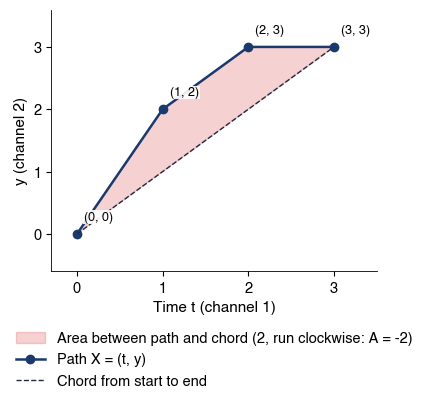

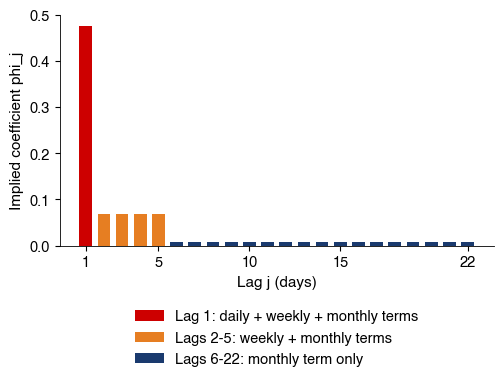

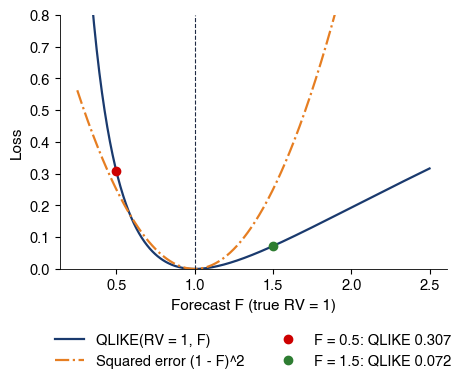

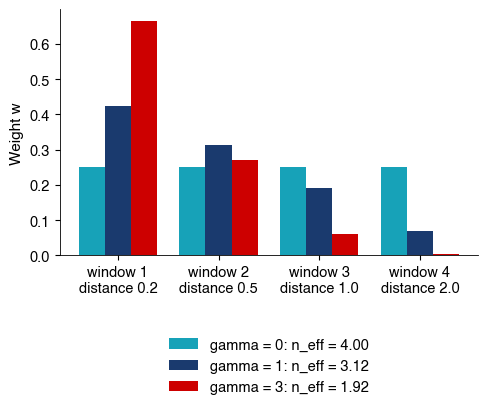

phi1                                                 0.476327
phi2                                                 0.068771
phi6                                                 0.008915
sum                                                  0.902972
N                                                        2764
b_logavg    [-1.1454868994670173, 0.41058379337011, 0.2477...
phi_min                                              0.008915
dtype: object

In [10]:
# Rezolvare
part_a()
pd.Series(RES['A']['a5']).drop(['b', 'se'])

### A8. Testarea restricțiilor HAR [Propus]

- Model: A7. Testul Wald al celor 19 restricții cu o covarianță Newey-West.

**Cerințe.**
1. Numărați restricțiile liniare și scrieți-le ca $R\phi = 0$.
2. Scrieți statistica Wald cu o covarianță HAC (robustă la heteroscedasticitate și autocorelație) și distribuția ei sub $H_0$.
3. Precizați valoarea critică la 5%.

**Interpretare**: dacă testul respinge într-un eșantion lung, ar trebui să renunțăm la HAR pentru prognoză?

In [11]:
# Codul vostru aici


### A2. QLIKE: minimizant și asimetrie [Rezolvat]

In [12]:
# Rezolvare
F = np.linspace(0.3, 3, 271)
rv = np.random.default_rng(1).lognormal(0, 0.8, 100000)
EL = [qlike(rv, f).mean() for f in F]
print('argmin of mean QLIKE:', F[np.argmin(EL)].round(2), ' mean RV:', rv.mean().round(2))
print('QLIKE(1, 0.5) =', qlike(1.0, 0.5).round(3), ' QLIKE(1, 1.5) =', qlike(1.0, 1.5).round(3))

argmin of mean QLIKE: 1.37  mean RV: 1.37
QLIKE(1, 0.5) = 0.307  QLIKE(1, 1.5) = 0.072


### A9. QLIKE cu argumentele inversate [Propus]

- Model: A2.

**Cerințe.**
1. Găsiți prognoza $F^\dagger$ care minimizează $E_t[L(RV, F)]$ pentru pierderea inversată $L(RV, F) = F/RV - \ln(F/RV) - 1$.
2. Comparați $F^\dagger$ cu $E_t[RV]$ folosind inegalitatea lui Jensen.
3. Precizați ce modele favorizează pierderea inversată.

**Interpretare**: de ce poate trece această eroare de verificările elementare?

Presupuneți RV>0 aproape sigur și o medie condiționată finită pentru 1/RV, astfel încît optimul pozitiv finit să existe.

In [13]:
# Codul vostru aici


### A3. Ponderi de nucleu și mărimea efectivă a eșantionului [Rezolvat]

În exp(-gamma*distance), gamma este inversa temperaturii: creșterea lui gamma concentrează ponderile. Parametrul calibrat c nu este neapărat gamma; folosiți conversia indicată.

In [14]:
# Rezolvare
d = np.array([0.2, 0.5, 1.0, 2.0])
for g in (1, 3):
    w = np.exp(-g * d) / np.exp(-g * d).sum()
    print(f'gamma = {g}: w = {w.round(3)}, n_eff = {1 / np.sum(w ** 2):.2f}')

gamma = 1: w = [0.425 0.315 0.191 0.07 ], n_eff = 3.12
gamma = 3: w = [0.666 0.271 0.06  0.003], n_eff = 1.92


### A10. Limitele temperaturii [Propus]

- Model: A3.

**Cerințe.**
1. Găsiți limitele ponderilor $w$ și ale lui $n_{\mathrm{eff}}$ cînd $c \to 0$.
2. Găsiți limitele cînd $c \to \infty$ (presupuneți că fereastra cea mai apropiată este unică).
3. Arătați că înmulțirea tuturor distanțelor cu $k > 0$ lasă ponderile neschimbate.

**Interpretare**: de ce este necesară scalarea cu mediana, $\gamma = c/\mathrm{mediana}(\delta)$, pentru a compara $c$ între 50 de active?

In [15]:
# Codul vostru aici


## Partea B — semnături și volatilitate pe VOLARE

### B1. Aria Lévy ca predictor al volatilității (JPM) [Rezolvat]

- Interpretare:
  - de ce 22 de laguri Newey-West?
  - este creșterea lui $R^2$ relevantă economic?

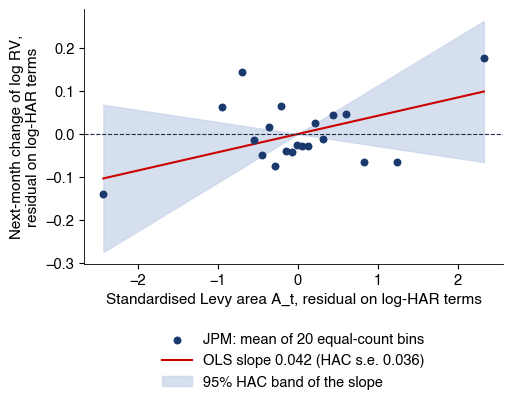

Levy-area coefficient                     0.0425
HAC standard error                        0.0360
t-statistic                               1.1817
R2 with the Levy area                     0.2856
R2 of log-HAR alone                       0.2802
observations                           2743.0000
mean Levy area                            0.0017
share of windows with negative area       0.4629
dtype: float64

In [16]:
# Rezolvare
pd.Series(levy_regression('stocks', 'JPM', 'ch20_sem_b1_levy')).rename(LEVY_LABELS).round(4)

### B5. Aria Lévy pentru futures E-mini S&P 500 [Propus]

- Model: B1.

**Cerințe.**
1. Repetați pașii (a)–(d) din B1 pentru ES (ținta, regresorii și cele 22 de laguri Newey–West ca în B1).
2. Testați coeficientul lui $A_t$ la 1% și la 5%, bilateral.
3. Comparați cîștigul de $R^2$ cu cel pentru JPM.

**Interpretare**: ce spune un coeficient pozitiv despre ferestrele cu arie negativă și poate semnul singur să le eticheteze drept episoade de leverage?

In [17]:
# Codul vostru aici


### B2. HAR, SHAR și HARQ pentru JPM, cu erori HAC [Rezolvat]

- Interpretare: se confirmă asimetria dintre volatilitatea „bună” și cea „rea” și efectul HARQ pentru JPM?

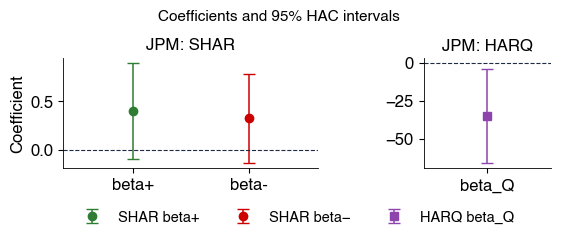

SHAR: beta- minus beta+ = -0.0778, t = -0.17, one-sided p = 0.5664
HARQ: t-statistic of beta_Q = -2.20  (observations: 2764)


coefficient  HAC s.e.
SHAR constant                       0.0000    0.0000
     RV+ (day)                      0.4014    0.2518
     RV- (day)                      0.3235    0.2357
     RV week                        0.4962    0.1542
     RV month                      -0.0248    0.0927
HARQ constant                       0.0000    0.0000
     RV day                         0.7007    0.1508
     RV day x (RQ^1/2 - mean)     -35.0623   15.9039
     RV week                        0.3928    0.1338
     RV month                      -0.0723    0.0910

In [18]:
# Rezolvare
har_table(har_family('stocks', 'JPM'))

### B6. HAR, SHAR și HARQ pentru petrol [Propus]

- Model: B2.

**Cerințe.**
1. Estimați SHAR și testați $\beta^{-} > \beta^{+}$ ca în B2(b).
2. Estimați HARQ și testați $\beta_Q < 0$ ca în B2(c); reprezentați coeficienții cu intervale HAC de 95%.
3. Comparați ambele rezultate cu JPM.

**Interpretare**: de ce ar putea fi asimetria mai puternică pentru o marfă decît pentru o acțiune bancară?

In [19]:
# Codul vostru aici


### B3. Sig-LK față de log-HAR pentru JPM, la o zi [Rezolvat]

- Interpretare: există vreo dovadă că semnătura aduce valoare pentru JPM?

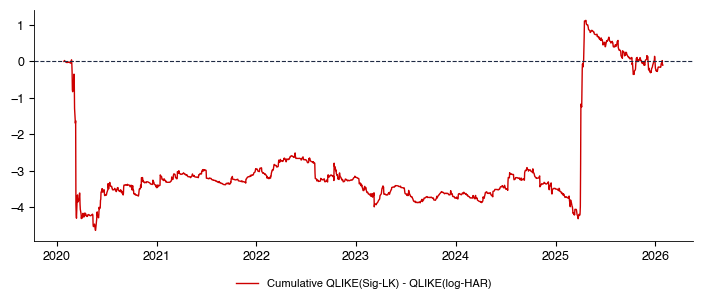

forecast days                                                            1511
first forecast                                                     2020-01-27
last forecast                                                      2026-01-29
mean QLIKE, Sig-LK                                                    0.17262
mean QLIKE, log-HAR                                                  0.172687
QLIKE ratio Sig-LK / log-HAR                                         0.999612
95% bootstrap CI of the ratio         [0.956148549523607, 1.0470004444676588]
DM t-statistic                                                       -0.01721
DM p-value, one-sided                                                0.493134
DM p-value, two-sided                                                0.986269
GW statistic                                                         2.845276
GW p-value                                                           0.241077
mean number of selected regressors                              

In [20]:
# Rezolvare
c1, _, cut1 = tuned(lecture_results(), 'stocks', 1)
b5, fc5 = sig_vs_loghar('stocks', 'JPM', 1, c1, cut1)
d = (qlike(fc5.y, fc5['Sig-LK']) - qlike(fc5.y, fc5['logHAR'])).cumsum()
fig, ax = plt.subplots(figsize=(8.5, 3))
ax.plot(d.index, d, color=IDAred, lw=1, label='Cumulative QLIKE(Sig-LK) - QLIKE(log-HAR)')
ax.axhline(0, color=Gray, ls='--', lw=0.8)
legend_outside_bottom(ax, ncol=1, y=-0.12)
plt.show()
pd.Series(b5).rename(DM_LABELS)

### B7. Sig-LK față de log-HAR pentru ES, la o săptămînă [Propus]

- Model: B3.

**Cerințe.**
1. Produceți prognoze săptămînale ($h = 5$) Sig-LK și log-HAR cu designul din B3 și temperatura $c$ aleasă pe blocul de validare al contractelor futures.
2. Calculați raportul QLIKE și intervalul său de încredere (CI) de 95% prin bootstrap staționar (lungimea medie a blocului 10).
3. Rulați testul Diebold–Mariano (DM) (lățime de bandă cel puțin $h = 5$) și testul Giacomini–White (GW) condiționat; reprezentați diferența cumulată de pierdere.

**Interpretare**: de ce este CI atît de asimetric și ce implică pentru puterea testului DM?

In [21]:
# Codul vostru aici


### B4. Holm și BH, pas cu pas [Rezolvat]

- Familia: 50 de p-value-uri DM unilaterale, Sig-LK mai bun decît log-HAR la $h = 1$.

In [22]:
# Rezolvare
pv = pd.Series(lecture_results()['dm_p']['1']['Sig-LK|logHAR']).sort_values()
tab = pd.DataFrame({'p': pv, 'Holm': holm(pv.values), 'BH': bh(pv.values)})
print('rejections raw/Holm/BH:', (tab.p < 0.05).sum(), (tab.Holm < 0.05).sum(), (tab.BH < 0.05).sum())
tab.head(8).round(4)

rejections raw/Holm/BH: 2 0 0


,p,Holm,BH
futures|ES,0.0018,0.0904,0.0904
stocks|TSLA,0.0279,1.0000,0.6979
forex|EURUSD,0.0709,1.0000,0.9730
forex|USDJPY,0.2130,1.0000,0.9730
futures|GC,0.2278,1.0000,0.9730
stocks|PG,0.2289,1.0000,0.9730
stocks|SHW,0.2593,1.0000,0.9730
stocks|GE,0.3166,1.0000,0.9730


### B8. Testare multiplă la o lună față de HAR [Propus]

- Model: B4.

**Cerințe.**
1. Numărați respingerile la 5% fără corecție, dintre cele 50 de p-value-uri DM unilaterale din Cursul 20 pentru „Sig-LK mai bun decît HAR” la $h = 22$ (QLIKE).
2. Aplicați Holm și BH ca în B4, numărați respingerile și numiți activul cu cea mai mică p-value.
3. Comparați cu raportul QLIKE mediu al Sig-LK față de HAR la $h = 22$, agregat pe cele 50 de active (Cursul 20).

**Interpretare**: cum poate Sig-LK să fie superior HAR pe mai multe active și totuși inferior în medie?

In [23]:
# Codul vostru aici


## Partea C — probleme deschise

### C2. Un nucleu de semnătură sensibil la nivel [Propus]

- Nucleul cu punct de bază față de nucleul simplu și de log-HAR, la o zi. Începeți cu trei acțiuni (de exemplu JPM, XOM, NVDA); studiul complet le folosește pe toate cele 40.

**Cerințe.**
1. Scrieți o preînregistrare de o pagină: 40 de acțiuni, $h = 1$, designul din curs, temperatura $c$ calibrată pentru acțiuni la $h = 1$, QLIKE, DM cu Holm, subperioada COVID-19 raportată separat.
2. Implementați nucleul cu punct de bază (folosiți actualizarea Chen din funcțiile seminarului) cu aceleași trăsături ca Sig-LK și prognozați.
3. Comparați cu Sig-LK și log-HAR: rapoartele QLIKE medii (toate zilele și COVID-19), numărul activelor cu rezultate semnificativ mai bune față de log-HAR, fără corecție și după Holm.

**Interpretare**: dacă sensibilitatea la nivel nu ajută, unde ați căuta în continuare (trăsături, țintă, orizont)?

In [24]:
# Codul vostru aici


### C1. Critica unui răspuns AI [Propus]

- **Cererea studentului**: „`rv` conține RV zilnică la 5 minute a unei acțiuni. Construiește LASSO-ul pe semnături al lui Gu et al. pentru log RV din ziua următoare și evaluează-l cu QLIKE pe ultimele 30% din eșantion.”
- **Răspunsul asistentului AI**:

```python
lrv = np.log(rv.values)
S = np.array([sig_path(lrv[t-21:t+1, None], depth=3)   # 22-day window
              for t in range(21, len(lrv) - 1)])
y = lrv[22:]                                            # next-day log RV
lam = LassoCV(cv=5).fit(S, y).alpha_                    # choose lambda
cut = int(0.7 * len(y))
m = Lasso(alpha=lam).fit(S[:cut], y[:cut])
f = np.exp(m.predict(S[cut:]))
qlike = lambda a, b: a / b - np.log(a / b) - 1
print(qlike(f, np.exp(y[cut:])).mean())
```

- *„LASSO-ul pe semnături are o valoare QLIKE mai mică decît HAR pe setul de test, deci semnăturile surprind forma volatilității și îmbunătățesc prognoza.”*

**Cerințe.** (a) Identificați cel puțin trei erori (numiți rîndul, explicați de ce este greșit). (b) Pentru fiecare, descrieți o verificare care o dezvăluie fără să știți răspunsul. (c) Evaluați retransformarea exponențială și dacă programul implementează metoda ponderată în doi pași a lui Gu et al. (d) Scrieți codul corectat și comparați-l cu log-HAR pe aceeași împărțire, cu un test DM. (e) Documentați fiecare eroare ca în `AI_ERRORS.md`.

În codul AI afișat, sig_path primește vîrfurile unei traiectorii liniare pe segmente și omite nivelul 0. Folosiți seria furnizată a varianței realizate JPM la cinci minute.

In [25]:
# Codul vostru aici
